# SMS Spam Classifier — Logistic Regression from Scratch

**Goal:** classify SMS messages as Ham (0) or Spam (1). The classifier is implemented with NumPy. Scikit-learn is used for train/test splitting, TF-IDF and evaluation utilities.

Workflow: load data → explore → clean → encode labels → split → TF-IDF → implement Logistic Regression → train → evaluate → test messages → save artifacts.

## 1. Import Libraries
Import libraries for data handling, visualization, vectorization, evaluation and saving artifacts.

In [1]:
import re, string, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
pd.set_option("display.max_colwidth", 120)

## 2. Load Dataset
The SMS Spam Collection file is tab-separated, has no header, and contains `label` and `message`. Place it at `data/SMSSpamCollection`.

In [2]:
candidate_paths = [Path("../data/SMSSpamCollection"), Path("data/SMSSpamCollection")]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place SMSSpamCollection inside the project's data folder.")
df = pd.read_csv(DATA_PATH, sep="\t", names=["label", "message"], encoding="utf-8")
print("Shape:", df.shape)
display(df.head())

Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 3. Explore Dataset
Inspect data types, missing values, duplicates, and ham/spam counts before preprocessing.

In [3]:
df.info()
print("\nMissing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df["label"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB

Missing values:


label      0
message    0
dtype: int64

Duplicate rows: 403


label
ham     4825
spam     747
Name: count, dtype: int64

## 4. Remove Duplicates
Remove repeated rows before splitting the data.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate removal:", df.shape)

Shape after duplicate removal: (5169, 2)


## 5. Class Distribution
Check the number and percentage of ham and spam messages. The dataset may be imbalanced.

,count,percentage
label,,
ham,4516,87.37
spam,653,12.63


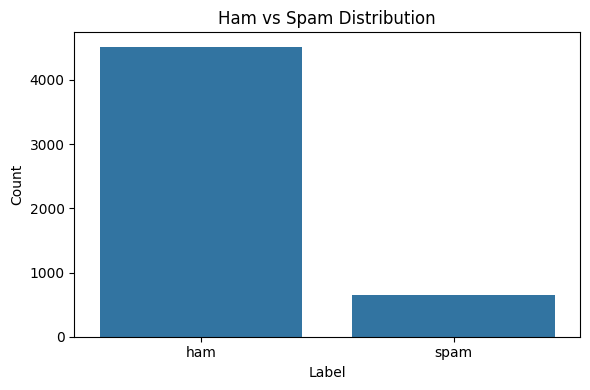

In [5]:
display(pd.DataFrame({"count": df["label"].value_counts(), "percentage": (df["label"].value_counts(normalize=True)*100).round(2)}))
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="label")
plt.title("Ham vs Spam Distribution")
plt.xlabel("Label"); plt.ylabel("Count"); plt.tight_layout(); plt.show()

## 6. Text Preprocessing
Convert text to lowercase, remove punctuation, normalize whitespace, and trim leading/trailing spaces. Keep the same cleaning function for future messages.

In [6]:
def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    return re.sub(r"\s+", " ", text).strip()

df["clean_message"] = df["message"].apply(clean_text)
display(df[["message", "clean_message"]].head())

,message,clean_message
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry questionstd txt...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives around here though",nah i dont think he goes to usf he lives around here though


## 7. Encode Labels
Map `ham` to 0 and `spam` to 1. These are the target values for binary classification.

In [7]:
df["label_encoded"] = df["label"].map({"ham": 0, "spam": 1})
print("Missing encoded labels:", df["label_encoded"].isna().sum())
display(df[["label", "label_encoded"]].head())

Missing encoded labels: 0


,label,label_encoded
0,ham,0
1,ham,0
2,spam,1
3,ham,0
4,ham,0


## 8. Features and Target
`X` contains cleaned SMS messages. `y` contains encoded target labels.

In [8]:
X = df["clean_message"]
y = df["label_encoded"].astype(int)
print("X:", X.shape, "y:", y.shape)

X: (5169,) y: (5169,)


## 9. Train-Test Split
Use 80% for training and 20% for testing. `stratify=y` preserves class proportions in both sets. `random_state=42` makes the split reproducible.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Train class %:"); display(y_train.value_counts(normalize=True)*100)
print("Test class %:"); display(y_test.value_counts(normalize=True)*100)

X_train: (4135,)
X_test: (1034,)
y_train: (4135,)
y_test: (1034,)
Train class %:


label_encoded
0    87.376058
1    12.623942
Name: proportion, dtype: float64

Test class %:


label_encoded
0    87.330754
1    12.669246
Name: proportion, dtype: float64

## 10. TF-IDF Vectorization
Raw text cannot be used directly by our numerical model. TF-IDF converts words into numerical features. Term Frequency measures how often a term appears in a message; Inverse Document Frequency reduces the weight of terms common across many messages. Fit the vectorizer only on training text, then transform test text with the fitted vectorizer to prevent data leakage.

In [10]:
tfidf = TfidfVectorizer(max_features=5000, min_df=2, ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("Train TF-IDF:", X_train_tfidf.shape)
print("Test TF-IDF:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Train TF-IDF: (4135, 5000)
Test TF-IDF: (1034, 5000)
Vocabulary size: 5000


## 11. Inspect TF-IDF Features
Rows represent messages and columns represent vocabulary features. The matrix is sparse because most messages contain only a small portion of the vocabulary.

In [11]:
feature_names = tfidf.get_feature_names_out()
tfidf_preview = pd.DataFrame(X_train_tfidf[:5].toarray(), columns=feature_names)
display(tfidf_preview.iloc[:, :20])

,020603,020603 this,07xxxxxxxxx,0800,0800 542,08000839402,08000839402 or,08000930705,08000930705 for,08001950382,08001950382 or,08712300220,08712300220 quoting,08712405020,08712460324,08715705022,08718720201,10,100,100 free
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 12. Logistic Regression Theory
The model calculates `z = XW + b`, then applies sigmoid: `sigmoid(z) = 1 / (1 + exp(-z))`. The output is the estimated spam probability. A probability >= 0.5 is classified as spam; otherwise ham. We keep TF-IDF matrices sparse to reduce memory use.

### 12.1 Implement Logistic Regression with NumPy
The implementation includes sigmoid, binary cross-entropy loss, gradient descent, L2 regularization, probability prediction, and class prediction. It supports sparse TF-IDF matrices.

In [12]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.5, epochs=1000, l2=0.01):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        if self.weights is None:
            raise ValueError("Model has not been trained.")
        z = np.asarray(X @ self.weights).reshape(-1) + self.bias
        return self.sigmoid(z)

    def compute_loss(self, y, p):
        eps = 1e-12
        p = np.clip(p, eps, 1 - eps)
        data_loss = -np.mean(y*np.log(p) + (1-y)*np.log(1-p))
        reg_loss = (self.l2 / (2*len(y))) * np.sum(self.weights**2)
        return float(data_loss + reg_loss)

    def fit(self, X, y):
        y = np.asarray(y, dtype=float).reshape(-1)
        n_samples, n_features = X.shape
        if n_samples != len(y):
            raise ValueError("X and y have different sample counts.")
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []
        for epoch in range(self.epochs):
            p = self.predict_proba(X)
            error = p - y
            dw = np.asarray(X.T @ error).reshape(-1) / n_samples
            dw += (self.l2 / n_samples) * self.weights
            db = float(np.mean(error))
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            if epoch == 0 or (epoch + 1) % 10 == 0:
                self.loss_history.append(self.compute_loss(y, self.predict_proba(X)))
        return self

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## 13. Train the Model
Initialize the model and train it using the TF-IDF training matrix and training labels. These hyperparameters are starting values and can be tuned after evaluation.

In [13]:
model = LogisticRegressionScratch(learning_rate=0.5, epochs=1000, l2=0.01)
model.fit(X_train_tfidf, y_train.to_numpy())
print("Training complete")
print("Weights:", len(model.weights))
print("Bias:", model.bias)
print("Final recorded loss:", model.loss_history[-1])

Training complete
Weights: 5000
Bias: -2.0093004026702097
Final recorded loss: 0.25101294945815195


## 14. Visualize Training Loss
A generally decreasing loss curve suggests the optimization process is reducing the training objective. An unstable or increasing curve may indicate a learning-rate or implementation issue.

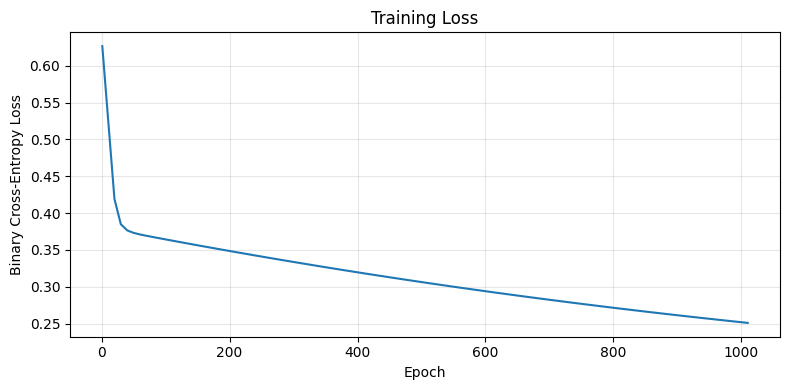

In [14]:
loss_epochs = np.arange(1, len(model.loss_history)+1) * 10
loss_epochs[0] = 1
plt.figure(figsize=(8,4))
plt.plot(loss_epochs, model.loss_history)
plt.title("Training Loss")
plt.xlabel("Epoch"); plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 15. Generate Test Predictions
Generate probabilities and binary predictions for the held-out test messages. The test set was not used to fit the vectorizer or train the model.

In [15]:
y_test_array = y_test.to_numpy()
y_test_probabilities = model.predict_proba(X_test_tfidf)
y_test_predictions = model.predict(X_test_tfidf)
print("Number of predictions:", len(y_test_predictions))
print("First 10 classes:", y_test_predictions[:10])
print("First 10 probabilities:", np.round(y_test_probabilities[:10], 4))

Number of predictions: 1034
First 10 classes: [0 0 0 0 0 0 0 0 0 0]
First 10 probabilities: [0.0838 0.0787 0.099  0.1311 0.0781 0.1309 0.1048 0.0742 0.1021 0.1061]


## 16. Evaluate Model Performance
Accuracy measures overall correctness. Precision measures how many predicted spam messages are actually spam. Recall measures how many actual spam messages are detected. F1 is the harmonic mean of precision and recall. Because the dataset is imbalanced, do not judge the model by accuracy alone.

In [16]:
accuracy = accuracy_score(y_test_array, y_test_predictions)
precision = precision_score(y_test_array, y_test_predictions, zero_division=0)
recall = recall_score(y_test_array, y_test_predictions, zero_division=0)
f1 = f1_score(y_test_array, y_test_predictions, zero_division=0)
metrics = {"accuracy": float(accuracy), "precision": float(precision), "recall": float(recall), "f1_score": float(f1)}
for name, value in metrics.items():
    print(f"{name.title()}: {value*100:.2f}%")
print("\nClassification report:")
print(classification_report(y_test_array, y_test_predictions, target_names=["Ham", "Spam"], zero_division=0))

Accuracy: 87.43%
Precision: 100.00%
Recall: 0.76%
F1_Score: 1.52%

Classification report:
              precision    recall  f1-score   support

         Ham       0.87      1.00      0.93       903
        Spam       1.00      0.01      0.02       131

    accuracy                           0.87      1034
   macro avg       0.94      0.50      0.47      1034
weighted avg       0.89      0.87      0.82      1034



## 17. Confusion Matrix
True Negative: ham correctly predicted ham. False Positive: ham incorrectly predicted spam. False Negative: spam incorrectly predicted ham. True Positive: spam correctly predicted spam.

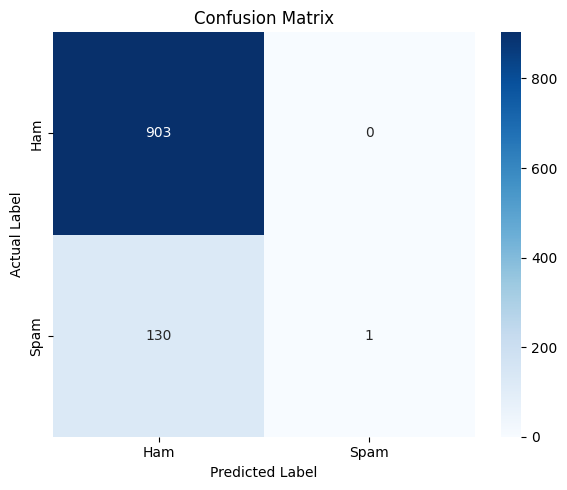

[[903   0]
 [130   1]]


In [17]:
cm = confusion_matrix(y_test_array, y_test_predictions)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label"); plt.ylabel("Actual Label")
plt.tight_layout(); plt.show()
print(cm)

## 18. Inspect Prediction Probabilities
Logistic Regression outputs spam probability. Ham probability is one minus spam probability. Confidence is the probability assigned to the predicted class; it is not a guarantee that the prediction is correct.

In [18]:
probability_results = pd.DataFrame({
    "message": X_test.reset_index(drop=True),
    "actual_label": y_test_array,
    "predicted_label": y_test_predictions,
    "spam_probability": y_test_probabilities,
    "ham_probability": 1-y_test_probabilities
})
probability_results["predicted_class"] = probability_results["predicted_label"].map({0: "Ham", 1: "Spam"})
probability_results["confidence"] = np.maximum(probability_results["spam_probability"], probability_results["ham_probability"])
display(probability_results.head(10))

,message,actual_label,predicted_label,spam_probability,ham_probability,predicted_class,confidence
0,good morning my love i go to sleep now and wish you a great day full of feeling better and opportunity you are my la...,0,0,0.083759,0.916241,Ham,0.916241
1,and how you will do that princess,0,0,0.078702,0.921298,Ham,0.921298
2,cool ill text you when im on the way,0,0,0.099015,0.900985,Ham,0.900985
3,your right ill make the appointment right now,0,0,0.131129,0.868871,Ham,0.868871
4,aiya we discuss later lar pick ü up at 4 is it,0,0,0.078102,0.921898,Ham,0.921898
5,maybe say hi to and find out if got his card great escape or wetherspoons,0,0,0.130939,0.869061,Ham,0.869061
6,lemme know when i can swing by and pick up im free basically any time after 1 all this semester,0,0,0.104836,0.895164,Ham,0.895164
7,yes please leave at ltgt so that at ltgt we can leave,0,0,0.074168,0.925832,Ham,0.925832
8,i am in bus on the way to calicut,0,0,0.102123,0.897877,Ham,0.897877
9,o we cant see if we can join denis and mina or does denis want alone time,0,0,0.106069,0.893931,Ham,0.893931


## 19. Test Custom SMS Messages
Apply the same cleaning function and the already-fitted TF-IDF vectorizer to new messages. Do not fit a new vectorizer for custom messages.

In [19]:
def predict_custom_message(message):
    cleaned = clean_text(message)
    features = tfidf.transform([cleaned])
    spam_probability = float(model.predict_proba(features)[0])
    ham_probability = 1 - spam_probability
    label = "SPAM" if spam_probability >= 0.5 else "HAM"
    return {
        "message": message,
        "prediction": label,
        "spam_probability": spam_probability,
        "ham_probability": ham_probability,
        "confidence": max(spam_probability, ham_probability)
    }

custom_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting at the library today?",
    "URGENT! Claim your cash reward now.",
    "Can you call me when you reach home?"
]
for message in custom_messages:
    result = predict_custom_message(message)
    print("\nMessage:", result["message"])
    print("Prediction:", result["prediction"])
    print(f"Spam probability: {result['spam_probability']*100:.2f}%")
    print(f"Ham probability: {result['ham_probability']*100:.2f}%")
    print(f"Confidence: {result['confidence']*100:.2f}%")


Message: Congratulations! You have won a free prize. Claim now!
Prediction: HAM
Spam probability: 45.74%
Ham probability: 54.26%
Confidence: 54.26%

Message: Hey, are we meeting at the library today?
Prediction: HAM
Spam probability: 8.85%
Ham probability: 91.15%
Confidence: 91.15%

Message: URGENT! Claim your cash reward now.
Prediction: HAM
Spam probability: 34.34%
Ham probability: 65.66%
Confidence: 65.66%

Message: Can you call me when you reach home?
Prediction: HAM
Spam probability: 10.49%
Ham probability: 89.51%
Confidence: 89.51%


## 20. Save Model Artifacts
Save weights, bias, the fitted TF-IDF vectorizer, and held-out test metrics. The vectorizer must be saved because future messages need the same vocabulary and IDF values.

In [ ]:
model_dir_candidates = [Path("../models"), Path("models")]
MODEL_DIR = next((p for p in model_dir_candidates if p.parent.exists()), Path("models"))
MODEL_DIR.mkdir(parents=True, exist_ok=True)
np.save(MODEL_DIR / "weights.npy", model.weights)
np.save(MODEL_DIR / "bias.npy", np.array([model.bias]))
joblib.dump(tfidf, MODEL_DIR / "tfidf_vectorizer.joblib")
metrics_to_save = {
    **metrics,
    "confusion_matrix": cm.tolist(),
    "training_samples": int(len(y_train)),
    "test_samples": int(len(y_test)),
    "vocabulary_size": int(len(tfidf.vocabulary_))
}
with open(MODEL_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_to_save, f, indent=4)
print("Saved artifacts to:", MODEL_DIR.resolve())

Saved artifacts to: C:\Users\DELL\OneDrive\Documents\Supervised-ML-from-scratch\logistic-regression\Project\sms-spam-classifier\model


## 21. Reload and Verify Artifacts
Reload the saved files and generate a prediction to confirm the saved model can be used independently of the training objects.

In [21]:
loaded_weights = np.load(MODEL_DIR / "weights.npy")
loaded_bias = float(np.load(MODEL_DIR / "bias.npy")[0])
loaded_vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer.joblib")
test_message = "Congratulations! You have won a free prize."
features = loaded_vectorizer.transform([clean_text(test_message)])
z = float(np.asarray(features @ loaded_weights).reshape(-1)[0] + loaded_bias)
z = float(np.clip(z, -500, 500))
spam_probability = 1 / (1 + np.exp(-z))
print("Message:", test_message)
print("Spam probability:", round(spam_probability, 4))
print("Prediction:", "SPAM" if spam_probability >= 0.5 else "HAM")

Message: Congratulations! You have won a free prize.
Spam probability: 0.4115
Prediction: HAM


## 22. Conclusion and Streamlit Integration

This notebook builds an SMS spam classifier using Logistic Regression implemented with NumPy. We practiced data exploration, cleaning, label encoding, stratified splitting, TF-IDF, sigmoid, binary cross-entropy, gradient descent, regularization, evaluation metrics, confusion matrix analysis, prediction probabilities, and saving model artifacts.

### Streamlit Application
The Streamlit app loads `weights.npy`, `bias.npy`, `tfidf_vectorizer.joblib`, and `metrics.json`. It cleans the submitted message, transforms it with the saved vectorizer, calculates spam probability, and displays the predicted class and probabilities.

**Remember:** test accuracy is a dataset-level metric; confidence is the probability assigned to an individual message. They are not interchangeable.